# 36. Valid Sudoku
**Difficulty:** 🟡 Medium · **Topic:** Arrays and Hashing · **Pattern:** [Hash Lookup](README.md) · **LeetCode:** https://leetcode.com/problems/valid-sudoku/

## 💡 Concepts

**Core concept(s):** **Hash Lookup** with three families of **hash sets**: one set per row, one per column, one per 3×3 box.

**Why it applies here:**
- The board is valid when no digit repeats inside any row, any column, or any box.
- "Does this unit already contain this digit?" is a membership test, and a hash set answers it in O(1).
- Every filled cell belongs to exactly three units, so each cell costs three lookups and three inserts.

**Key intuition:**
- Scan the cells once.
- Before recording a digit, ask its row set, its column set and its box set: "seen this digit already?"
- Any "yes" is a repeat, so the board is invalid. Otherwise record the digit in all three sets and move on.
- The box of cell `(r, c)` is `(r // 3, c // 3)`: integer division groups rows 0–2, 3–5, 6–8 (and the same for columns).

---

### 📚 What is a Hash Set?
- A **hash set** stores unique values and answers "is `x` in here?" without scanning.
- It runs `x` through a *hash function* to pick a slot in an internal array, then looks only at that slot.
- Add / lookup / delete are **O(1) on average** (O(n) only in the rare worst case of many collisions).
- **In Python:** `set()`; add with `s.add(x)`, test with `x in s`.

### 📚 What is a Hash Map (dictionary)?
- A **hash map** stores key → value pairs and finds a key's value with the same hashing trick, **O(1) on average**.
- Here the keys are unit ids (a row number, a column number, or a box pair `(r // 3, c // 3)`) and each value is that unit's set of digits.
- **In Python:** `dict`; `collections.defaultdict(set)` creates an empty set the first time a key is used, so no "does this key exist yet?" check is needed.

---

**Prerequisite knowledge:**
- Integer division `//` (`7 // 3 == 2`).
- The Hash Lookup idea from [Contains Duplicate](contains_duplicate.ipynb): check "seen before?" **before** recording the current value.

## 📝 Problem

Decide whether a partially filled 9×9 Sudoku board is **valid**. Only the filled cells (`"1"`–`"9"`) are checked; empty cells are `"."`.

1. Each **row** contains each digit at most once.
2. Each **column** contains each digit at most once.
3. Each of the nine **3×3 boxes** contains each digit at most once.

A valid board does **not** have to be solvable: you only check the digits already on it.

**Example 1** → `True` (no repeats in any row, column or box)
```
5 3 . | . 7 . | . . .
6 . . | 1 9 5 | . . .
. 9 8 | . . . | . 6 .
------+-------+------
8 . . | . 6 . | . . 3
4 . . | 8 . 3 | . . 1
7 . . | . 2 . | . . 6
------+-------+------
. 6 . | . . . | 2 8 .
. . . | 4 1 9 | . . 5
. . . | . 8 . | . 7 9
```

**Example 2** → `False`: the same board with the top-left `5` changed to `8`. Column 0 now holds two 8s (rows 0 and 3), and the top-left box holds two 8s (`(0,0)` and `(2,2)`).

**Constraints:** `board.length == 9`, `board[i].length == 9`, `board[i][j]` is a digit `1-9` or `"."`.

> Two approaches: a brute force that rescans each filled cell's row, column and box, and the one-pass hash-set version (the pattern template). The code below works for any `n×n` board with `n = b²` (box width `b`), so the benchmark can grow the board; LeetCode always uses `n = 9`, `b = 3`.

In [1]:
from typing import List
from math import isqrt
from collections import defaultdict

def board_from_rows(rows: List[str]) -> List[List[str]]:
    """Turn ["53..7....", ...] into LeetCode's list-of-lists-of-strings board."""
    return [list(r) for r in rows]

EXAMPLE_1 = board_from_rows([
    "53..7....",
    "6..195...",
    ".98....6.",
    "8...6...3",
    "4..8.3..1",
    "7...2...6",
    ".6....28.",
    "...419..5",
    "....8..79",
])
EXAMPLE_2 = [row[:] for row in EXAMPLE_1]
EXAMPLE_2[0][0] = "8"                    # LeetCode example 2: the only change

def full_board(b: int) -> List[List[str]]:
    """A completely filled, VALID n x n board (n = b*b): every row, column and box holds 1..n once.
    Shifted-pattern construction; used for tests and as the benchmark's no-early-exit input."""
    n = b * b
    return [[str(((r % b) * b + r // b + c) % n + 1) for c in range(n)] for r in range(n)]

### Approach 1 — Brute Force: rescan every filled cell's row, column and box

**Idea:**
1. Visit every filled cell `(r, c)` holding digit `v`.
2. Walk its whole row and whole column; if any *other* cell holds `v`, the board is invalid.
3. Work out the top-left corner of its box (`(r // b) * b, (c // b) * b`) and walk the `b×b` box the same way.
4. If no cell ever finds a twin, the board is valid.

No extra memory, but every cell rescans its `3n` peers, and each pair of cells is compared twice (once from each side).

**Time complexity:** `O(n³)` for an `n×n` board — `n²` cells × about `3n` peers each. For LeetCode's fixed 9×9 board that is a constant (81 × 27 comparisons at most), i.e. `O(1)`.

**Space complexity:** `O(1)` — only loop indices.

In [2]:
def is_valid_sudoku_brute(board: List[List[str]]) -> bool:
    n = len(board)
    b = isqrt(n)                                   # box width: 3 for a 9x9 board
    for r in range(n):
        for c in range(n):
            v = board[r][c]
            if v == ".":                           # empty cells are never checked
                continue
            for k in range(n):
                if k != c and board[r][k] == v:    # another v in the same row
                    return False
                if k != r and board[k][c] == v:    # another v in the same column
                    return False
            br, bc = (r // b) * b, (c // b) * b    # top-left corner of this cell's box
            for rr in range(br, br + b):
                for cc in range(bc, bc + b):
                    if (rr != r or cc != c) and board[rr][cc] == v:   # another v in the same box
                        return False
    return True

### Approach 2 — One pass with three families of hash sets (optimal · pattern template)

**Idea:** the [Hash Lookup](README.md) template, run against three memories at once.
1. Keep `rows[r]`, `cols[c]` and `boxes[(r // b, c // b)]`: each is a set of the digits already seen in that unit.
2. Scan the cells once, row by row. Skip `"."`.
3. **Check before you record:** if `v` is already in its row set, column set or box set, a unit has a repeat → return `False`.
4. Otherwise add `v` to all three sets and continue. Finishing the scan means no unit has a repeat → `True`.

**Time complexity:** `O(n²)` — each of the `n²` cells does three O(1) average lookups and three O(1) inserts. For the fixed 9×9 board: `O(1)` (at most 81 cells).

**Space complexity:** `O(n²)` — every filled cell's digit is stored three times (once per unit). For 9×9: at most 243 entries, `O(1)`.

> Both approaches are `O(1)` on LeetCode's fixed 9×9 board. The difference is the work per cell: three hash lookups instead of rescanning up to 27 peers. The benchmark below grows the board to make that visible.

In [3]:
def is_valid_sudoku_sets(board: List[List[str]]) -> bool:
    n = len(board)
    b = isqrt(n)                                   # box width: 3 for a 9x9 board
    rows = defaultdict(set)                        # row index      -> digits seen in that row
    cols = defaultdict(set)                        # column index   -> digits seen in that column
    boxes = defaultdict(set)                       # (r//b, c//b)   -> digits seen in that box
    for r in range(n):
        for c in range(n):
            v = board[r][c]
            if v == ".":                           # empty cells don't count
                continue
            box = (r // b, c // b)                 # which box this cell belongs to
            if v in rows[r] or v in cols[c] or v in boxes[box]:   # O(1) "seen before?" x3
                return False                       # a unit already holds v -> repeat
            rows[r].add(v)                         # record v AFTER the check,
            cols[c].add(v)                         # in all three units it belongs to
            boxes[box].add(v)
    return True

In [4]:
# Correctness check
import random

MINI_4x4 = board_from_rows([      # 4x4 board, 2x2 boxes: the 3 at (3,3) repeats the 3 at (2,2) in their box only
    "1..4",
    ".32.",
    ".43.",
    "2..3",
])

def with_cell(board, r, c, v):
    g = [row[:] for row in board]
    g[r][c] = v
    return g

EMPTY_9 = [["."] * 9 for _ in range(9)]
tests = [
    ("LeetCode example 1",                 EXAMPLE_1, True),
    ("LeetCode example 2 (col + box dup)", EXAMPLE_2, False),
    ("empty board",                        EMPTY_9,   True),
    ("row repeat only",                    with_cell(with_cell(EMPTY_9, 0, 0, "5"), 0, 8, "5"), False),
    ("column repeat only",                 with_cell(with_cell(EMPTY_9, 0, 4, "7"), 8, 4, "7"), False),
    ("box repeat only (diagonal)",         with_cell(with_cell(EMPTY_9, 3, 3, "2"), 5, 5, "2"), False),
    ("same digit, different units",        with_cell(with_cell(EMPTY_9, 0, 0, "9"), 4, 4, "9"), True),
    ("full valid 9x9",                     full_board(3), True),
    ("4x4 mini board (box-only repeat)",   MINI_4x4,  False),
]
for name, board, exp in tests:
    a, b = is_valid_sudoku_brute(board), is_valid_sudoku_sets(board)
    print(f"{name:36} -> brute={a!s:5} sets={b!s:5} | expected={exp}")
    assert a == b == exp, f"mismatch on {name}"

# Randomised cross-check: blank out cells of a full valid board, sometimes plant a random digit
rng = random.Random(36)
for _ in range(500):
    g = full_board(3)
    for r in range(9):
        for c in range(9):
            if rng.random() < 0.6:
                g[r][c] = "."
    if rng.random() < 0.5:                         # maybe introduce a repeat
        g[rng.randrange(9)][rng.randrange(9)] = str(rng.randint(1, 9))
    assert is_valid_sudoku_brute(g) == is_valid_sudoku_sets(g)
print("500 random boards: both approaches agree")

print("\nAll tests passed")

LeetCode example 1                   -> brute=True  sets=True  | expected=True
LeetCode example 2 (col + box dup)   -> brute=False sets=False | expected=False
empty board                          -> brute=True  sets=True  | expected=True
row repeat only                      -> brute=False sets=False | expected=False
column repeat only                   -> brute=False sets=False | expected=False
box repeat only (diagonal)           -> brute=False sets=False | expected=False
same digit, different units          -> brute=True  sets=True  | expected=True
full valid 9x9                       -> brute=True  sets=True  | expected=True
4x4 mini board (box-only repeat)     -> brute=False sets=False | expected=False
500 random boards: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured** by timing growing inputs and reading the ratio between consecutive sizes.

LeetCode's board is always 9×9, so both approaches are `O(1)` there. To see how the work per cell differs, the benchmark grows the board: the size column is the **box width `b`**, and the board is `n×n` with `n = b²`. Doubling `b` multiplies the side `n` by 4 and the number of cells `n²` by 16:

| Theoretical (in `n`) | Ratio when `b` → `2b` (`n` → `4n`) |
|----------------------|-------------------------------------|
| `O(n²)` (sets: one pass over the cells) | ≈ **16×** |
| `O(n³)` (brute: every cell rescans `3n` peers) | ≈ **64×** |

The input is a **completely filled valid board**, so neither approach can exit early. (The helper's footer line about "per doubling" refers to doubling `n`; here each step quadruples `n`, so use the table above.)


brute O(n^3)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        3 |       0.06 |           n/a
        6 |       3.67 |        56.95x


       12 |     226.24 |        61.71x

sets  O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        3 |       0.02 |           n/a
        6 |       0.29 |        14.76x
       12 |       5.38 |        18.38x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


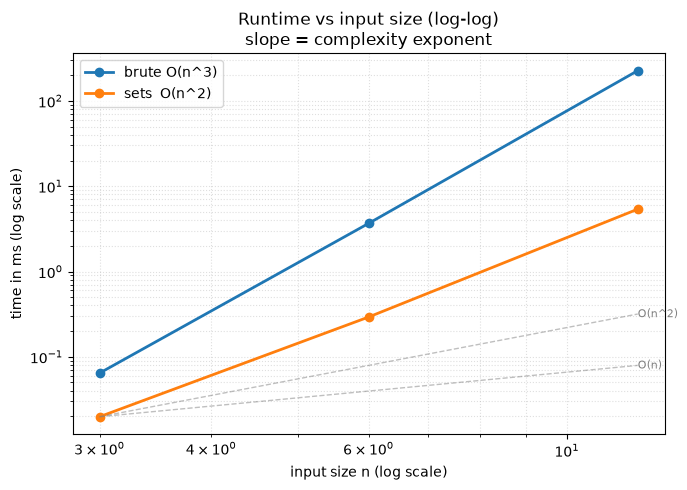

{'brute O(n^3)': [0.06437499541789293, 3.6660830955952406, 226.23845795169473],
 'sets  O(n^2)': [0.019832979887723923,
  0.29274995904415846,
  5.3811249090358615]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark   # shared: prints ratio table + optional log-log plot

def make_worst_case(b):
    return (full_board(b),)              # n = b*b, every cell filled, no repeats -> no early exit

solutions = {
    "brute O(n^3)": is_valid_sudoku_brute,
    "sets  O(n^2)": is_valid_sudoku_sets,
}
sizes = [3, 6, 12]                       # box width b -> boards 9x9, 36x36, 144x144

benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Hash Lookup](README.md) — the "seen before?" check from Contains Duplicate, run against three memories at once: one set per row, per column and per box, each answering in O(1).
- **Many units → a dictionary of sets:** when a value must be unique inside several overlapping groups, key a set by each group's id. The id can be computed: the box of `(r, c)` is `(r // 3, c // 3)`.
- **Check before you record:** test all three sets first, then add to all three. Adding first would make every digit find itself.
- **Signal:** "no repeats within each row / column / group", "each value at most once per unit", "validate a grid".
- **Related problems:** Contains Duplicate (one unit: the whole array), Sudoku Solver (backtracking, using the same three sets to test each candidate digit), N-Queens (sets for columns and both diagonals).
- **Common pitfalls:**
  1. Wrong box id: `r // 3 * 3 + c // 3` (a number 0–8) and `(r // 3, c // 3)` both work; `r // 3 + c // 3` does not (boxes `(0,1)` and `(1,0)` would collide).
  2. Checking validity as "solvable": the task only checks the digits already placed.
  3. Forgetting to skip `"."`, so empty cells count as repeats.
  4. Checking only rows and columns: a repeat that sits diagonally inside one box (e.g. `(3,3)` and `(5,5)`) is caught only by the box sets.